# 03 — Which tasks transfer to which? A mini transfer matrix + a cheap predictor (LEEP)

**Question.** Transfer is not one number — it is a *relation between tasks*.
Taskonomy (Zamir et al., CVPR 2018) mapped that relation across 26 vision
tasks and found rich, asymmetric structure: some sources transfer almost
everywhere, others barely help even close neighbors. Here we build the
miniature version — a 7-source × 3-target matrix of frozen-feature quality —
and then ask whether the **LEEP score** (Nguyen et al., ICML 2020), computed
from a *single forward pass* over target data with no target training at
all, predicts that matrix.

**What the literature says.**
- Task relatedness governs transfer, and the source→target relation is
  asymmetric — a transfer *matrix*, not a similarity score (Zamir et al.
  2018).
- Transferability can be estimated cheaply: LEEP runs the frozen source
  classifier on target images, forms the empirical joint between source
  softmax outputs and target labels, and scores the expected log-likelihood
  of a "dummy" classifier built from it (Nguyen et al. 2020). Higher = more
  transferable, and it costs seconds, not training runs.
- A trained source can be actively *bad*: networks trained on random labels
  memorize rather than generalize (Zhang et al. 2017), so their features
  need not beat — and may lose to — a random initialization.

That last point is why the matrix includes a `random-init` row: an encoder
that has never seen data. Random convolutional features are a famously
non-trivial baseline at small scale, so every trained source must clear
that row before we credit it with having *learned* anything transferable.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tllab").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

import tllab
from tllab import analysis, data, models, train

tllab.setup()

tllab: torch 2.13.0+cu130 | threads=4 | QUICK=False | root=/home/user/transfer-learning-lab


## Seven source models

The first six sources come from `train_or_load_source` with the shared
defaults (20k examples, 6 epochs, seed 0), so their checkpoints are shared
with every other notebook in the suite. The seventh, `random-init`, is a
freshly initialized `SmallCNN` with **no training at all** — the null row.

One source deserves a caveat up front: `mnist:randlabel` *cannot*
generalize on its own task (train and test labels are shuffled
independently, so its own test accuracy is chance, ~0.10). Everything it
"knows" is memorization — yet memorizing still reshapes its features
(Zhang et al. 2017), which is exactly what makes it an interesting row.

In [2]:
SOURCE_KEYS = ["mnist", "fashion", "mnist:rot90", "mnist:permuted",
               "mnist:randlabel", "mnist:rotpred", "random-init"]
TARGET_KEYS = ["mnist", "fashion", "mnist:rot90"]

sources = {key: train.train_or_load_source(key) for key in SOURCE_KEYS[:-1]}
sources["random-init"] = models.new_cnn(10, seed=0)  # the untrained null row

for key in SOURCE_KEYS:
    if key == "random-init":
        print(f"  {key:>15}: untrained (null model, seed 0)")
    else:
        acc = train.evaluate(sources[key], data.get_task(key))
        print(f"  {key:>15}: own-task test acc = {acc:.3f}")

[ckpt cached] mnist: test_acc=0.985


[ckpt cached] fashion: test_acc=0.864


[ckpt cached] mnist:rot90: test_acc=0.986
[ckpt cached] mnist:permuted: test_acc=0.916
[ckpt cached] mnist:randlabel: test_acc=0.101


[ckpt cached] mnist:rotpred: test_acc=0.984


            mnist: own-task test acc = 0.985


          fashion: own-task test acc = 0.864


      mnist:rot90: own-task test acc = 0.986


   mnist:permuted: own-task test acc = 0.916


  mnist:randlabel: own-task test acc = 0.101


    mnist:rotpred: own-task test acc = 0.984
      random-init: untrained (null model, seed 0)


## The measurement: frozen-feature quality, plus a no-training predictor

For every (source, target) pair we measure how good the source's *frozen*
features are for the target: freeze the encoder, train a linear head on
n = 1000 target labels (`tllab.q` scales this in QUICK mode), and average
over seeds. Probing happens inside a fixed 6000-example pooled subset per
target so each pair's embeddings are computed once and cached across seeds.

Alongside each probe we compute the pair's LEEP score once — a forward
pass of the source *classifier* (softmax included) over target images,
no gradient steps anywhere. If LEEP works, its ranking of the 21 pairs
should match the probe ranking that costs 21 × seeds actual head trainings.

In [3]:
def transfer_matrix() -> pd.DataFrame:
    n_probe = tllab.q(1000, 100)
    rows = []
    for tkey in TARGET_KEYS:
        pool = data.subset(data.get_task(tkey), tllab.q(6000, 1200), seed=99)
        for skey in SOURCE_KEYS:
            src = sources[skey]
            score = analysis.leep(src, pool)
            accs = []
            for seed in tllab.seeds():
                acc = train.linear_probe(src, pool, n_train=n_probe,
                                         seed=seed, cache_key="03-" + skey)
                accs.append(acc)
                rows.append({"source": skey, "target": tkey, "seed": seed,
                             "probe_acc": acc, "leep": score})
            print(f"  {skey:>15} -> {tkey:<11} "
                  f"probe={sum(accs) / len(accs):.3f}  leep={score:.3f}")
    return pd.DataFrame(rows)


df = train.cached_sweep("03_transfer_matrix", transfer_matrix)
df.pivot_table(index="source", columns="target", values="probe_acc").reindex(
    index=SOURCE_KEYS, columns=TARGET_KEYS).round(3)

[sweep cached] 03_transfer_matrix.csv


target,mnist,fashion,mnist:rot90
source,,,
mnist,0.980,0.731,0.900
fashion,0.853,0.872,0.874
mnist:rot90,0.917,0.725,0.980
mnist:permuted,0.838,0.725,0.858
mnist:randlabel,0.276,0.298,0.346
mnist:rotpred,0.728,0.658,0.746
random-init,0.608,0.614,0.590


figure -> artifacts/figures/03_transfer_matrix.png


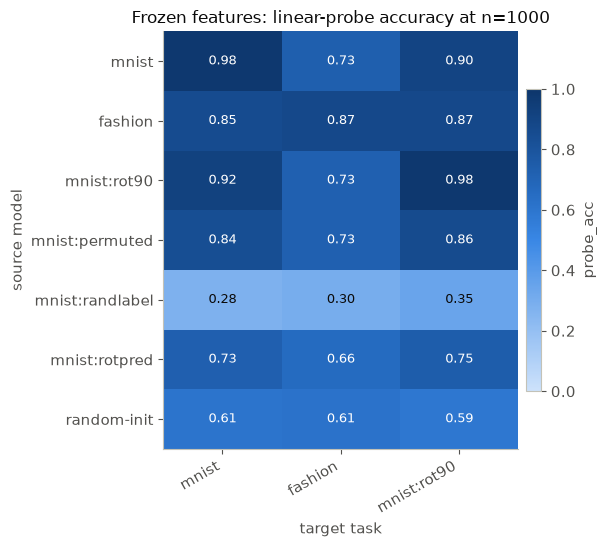

In [4]:
plt.figure(figsize=(6.2, 5.6))
analysis.plot_transfer_matrix(
    df, sources=SOURCE_KEYS, targets=TARGET_KEYS,
    title=f"Frozen features: linear-probe accuracy at n={tllab.q(1000, 100)}")
analysis.savefig("03_transfer_matrix")

## Reading the matrix

- **Self-transfer (the diagonal-ish cells) is strongest.** Each target's
  best source is itself — features trained *for* a task are best *at* it.
- **mnist ↔ rot90 transfer strongly in both directions.** A rotated digit
  is made of the same strokes and curves; the conv features barely care
  which way is up. Task relatedness, not dataset identity, is what counts.
- **Memorization poisons features; scrambled pixels merely dent them.**
  The `randlabel` row crashes ~30 points *below* the untrained
  `random-init` row: features shaped by pure memorization (Zhang et al.
  2017) are far worse than a random projection — the strongest negative-
  transfer signal in the matrix, developed further in notebook 04. The
  `permuted` row, by contrast, stays clearly above random-init: even with
  spatial structure destroyed, honest supervised training still learns
  pixel-statistics features that carry over. What the source *optimized
  for* matters more than what its inputs looked like.
- **Transfer is asymmetric.** `fashion→mnist` lands well above
  `mnist→fashion` — the texture-rich, harder source produces broader
  features than the sparse-stroke one, echoing the asymmetries Taskonomy
  found at scale (the transfer "distance" between two tasks depends on the
  direction you cross it).
- **`mnist:rotpred` (self-supervised, zero labels) lands only modestly
  above random-init here — and that is a *protocol* artifact.** This
  matrix probes each source's final 128-d embedding, and a pretext task's
  last block specializes to the pretext ("which way is up", not "which
  digit"). Probed at mid-depth instead, the same encoder scores ~0.92 on
  mnist — notebook 07 unpacks this layer story.
- **Honest scale caveat.** With a small CNN on 28×28 images, random conv
  features are already strong (random-init probes ~0.6), so the matrix's
  dynamic range is compressed compared to Taskonomy at full scale. The
  *ordering* of rows is the robust finding here, not the size of the gaps.

## Can we predict the matrix without training? (LEEP)

Each point below is one source→target pair: LEEP (computed in seconds) on
the x-axis, the measured probe accuracy on the y-axis. A high rank
correlation means the cheap score could have told us which source to pick
before running any probe.

figure -> artifacts/figures/03_leep_scatter.png


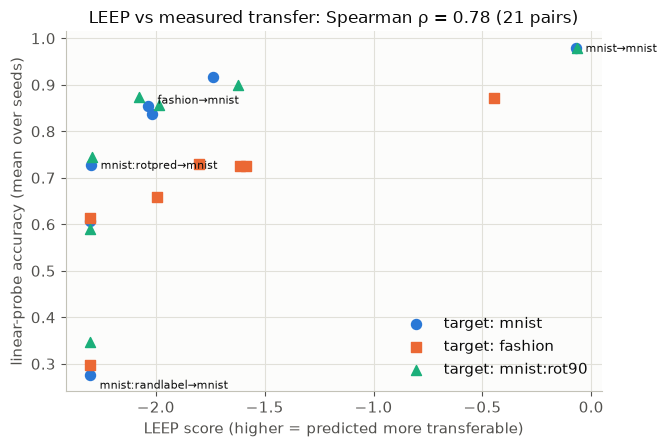

In [5]:
pair = (df.groupby(["source", "target"], as_index=False)
          .agg(probe_acc=("probe_acc", "mean"), leep=("leep", "mean")))
rho = analysis.spearman(pair["leep"], pair["probe_acc"])

plt.figure(figsize=(6.8, 4.6))
ax = plt.gca()
markers = ["o", "s", "^"]
for i, tkey in enumerate(TARGET_KEYS):
    g = pair[pair["target"] == tkey]
    ax.scatter(g["leep"], g["probe_acc"], s=52, color=tllab.PALETTE[i],
               marker=markers[i], label=f"target: {tkey}", zorder=3)

notable = {("mnist", "mnist"): (7, -3), ("mnist:rotpred", "mnist"): (7, -3),
           ("fashion", "mnist"): (7, 2), ("mnist:randlabel", "mnist"): (7, -10)}
for (skey, tkey), off in notable.items():
    r = pair[(pair["source"] == skey) & (pair["target"] == tkey)].iloc[0]
    ax.annotate(f"{skey}→{tkey}", (r["leep"], r["probe_acc"]),
                textcoords="offset points", xytext=off, fontsize=8,
                color="#0b0b0b")
ax.set_xlabel("LEEP score (higher = predicted more transferable)")
ax.set_ylabel("linear-probe accuracy (mean over seeds)")
ax.set_title(f"LEEP vs measured transfer: Spearman ρ = {rho:.2f} "
             f"({len(pair)} pairs)")
ax.legend()
analysis.savefig("03_leep_scatter")

## Takeaways

- **Transfer is a structured relation between tasks.** Self-transfer tops
  each column, near-duplicates (`mnist` ↔ `rot90`) transfer strongly both
  ways, cross-domain pairs sit in the middle — with a clear directional
  asymmetry (`fashion→mnist` ≫ `mnist→fashion`) — and the memorization
  source brings up the rear: a miniature Taskonomy.
- **"Trained" does not imply "transferable."** The `randlabel` row sits
  far *below* the untrained `random-init` row: features shaped by
  memorization are worse than a random projection. What the source was
  optimized for — not how much effort went into training it — is what
  transfers. (Honest-but-scrambled `permuted` still beats random.)
- **Where you tap the network matters as much as the source task.** The
  self-supervised `rotpred` source looks mediocre through this matrix's
  final-layer probe, yet its mid-depth features nearly match supervised
  ones (notebook 07) — a transferability measurement is always a joint
  property of (source task, layer, protocol).
- **A forward pass predicts most of the ranking.** LEEP's rank correlation
  with the probe results is substantially positive — a useful pre-flight
  check before committing to a source. It is not perfect: with only 21
  pairs, three targets, and MNIST-scale compression of the accuracy range,
  the correlation is real but noisy, so we state it as a soft claim below.

**References.** Zamir et al., *Taskonomy: Disentangling Task Transfer
Learning* (CVPR 2018). Nguyen et al., *LEEP: A New Measure to Evaluate
Transferability of Learned Representations* (ICML 2020). Zhang et al.,
*Understanding deep learning requires rethinking generalization*
(ICLR 2017). Gidaris, Singh & Komodakis, *Unsupervised Representation
Learning by Predicting Image Rotations* (ICLR 2018).

In [6]:
if not tllab.config.QUICK:
    piv = df.pivot_table(index="source", columns="target", values="probe_acc",
                         aggfunc="mean")
    mn = piv["mnist"]
    analysis.claim("mnist→mnist tops the mnist column",
                   mn["mnist"] >= mn.max(),
                   f"self={mn['mnist']:.3f}, "
                   f"best non-self={mn.drop('mnist').max():.3f}", hard=True)
    analysis.claim("randlabel features ≤ random-init on mnist (+2 pt slack)",
                   mn["mnist:randlabel"] <= mn["random-init"] + 0.02,
                   f"randlabel={mn['mnist:randlabel']:.3f} vs "
                   f"random-init={mn['random-init']:.3f}")
    pair_m = (df.groupby(["source", "target"], as_index=False)
                .agg(probe_acc=("probe_acc", "mean"), leep=("leep", "mean")))
    rho_all = analysis.spearman(pair_m["leep"], pair_m["probe_acc"])
    analysis.claim("LEEP rank-predicts probe accuracy (ρ > 0.5 over 21 pairs)",
                   rho_all > 0.5, f"Spearman ρ = {rho_all:.2f}")

CLAIM CHECK [PASS] mnist→mnist tops the mnist column — self=0.980, best non-self=0.917
CLAIM CHECK [PASS] randlabel features ≤ random-init on mnist (+2 pt slack) — randlabel=0.276 vs random-init=0.608
CLAIM CHECK [PASS] LEEP rank-predicts probe accuracy (ρ > 0.5 over 21 pairs) — Spearman ρ = 0.78
